## Model Development

This notebook focuses on developing and evaluating supervised machine learning models for cyberbullying detection. The processed datasets are loaded, transformed into numerical features using TF-IDF, and used to train and compare multiple classifiers. The best-performing model is then evaluated on a more recent dataset to assess its ability to generalize to evolving cyberbullying language.

## Importing libraries

In [4]:
# Data manipulation
import pandas as pd
import numpy as np

# Data splitting
from sklearn.model_selection import train_test_split

# Feature extraction
from sklearn.feature_extraction.text import TfidfVectorizer

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Visualization
import matplotlib.pyplot as plt

# Save models
import joblib

## Load the processed datasets

In [6]:
historical = pd.read_csv("historical_processed11.csv")
recent = pd.read_csv("recent_processed11.csv")

In [7]:
historical.head()

,text,label,clean_text,tokens,processed_text
0,"In other words #katandandre, your food was cra...",0,in other words katandandre your food was crapi...,"['word', 'katandandre', 'food', 'crapilicious'...",word katandandre food crapilicious mkr
1,Why is #aussietv so white? #MKR #theblock #ImA...,0,why is aussietv so white mkr theblock imaceleb...,"['aussietv', 'white', 'mkr', 'theblock', 'imac...",aussietv white mkr theblock imacelebrityau tod...
2,@XochitlSuckkks a classy whore? Or more red ve...,0,a classy whore or more red velvet cupcakes,"['classy', 'whore', 'red', 'velvet', 'cupcake']",classy whore red velvet cupcake
3,"@Jason_Gio meh. :P thanks for the heads up, b...",0,meh p thanks for the heads up but not too conc...,"['meh', 'p', 'thanks', 'head', 'not', 'concern...",meh p thanks head not concerned another angry ...
4,@RudhoeEnglish This is an ISIS account pretend...,0,this is an isis account pretending to be a kur...,"['isi', 'account', 'pretending', 'kurdish', 'a...",isi account pretending kurdish account like is...


In [8]:
recent.head()

,text,label,clean_text,tokens,processed_text
0,Say this to everyone who thinks that it’s ok t...,1,say this to everyone who thinks that it’s ok t...,"['say', 'everyone', 'think', 'ok', 'judge', 'a...",say everyone think ok judge anyone u without k...
1,One word for this chutiya Guswami 😂 #ArnabGosw...,1,one word for this chutiya guswami arnabgoswami,"['one', 'word', 'chutiya', 'guswami', 'arnabgo...",one word chutiya guswami arnabgoswami
2,Joined Tribe Membership 😊 @BewakoofBrands #bew...,0,joined tribe membership bewakoof tribemember,"['joined', 'tribe', 'membership', 'bewakoof', ...",joined tribe membership bewakoof tribemember
3,#PUBGMOBILE #PUBG is a south Korean app not C...,1,pubgmobile pubg is a south korean app not chin...,"['pubgmobile', 'pubg', 'south', 'korean', 'app...",pubgmobile pubg south korean app not chinese w...
4,I will purchase d mobile.but technical problem...,0,i will purchase d mobilebut technical problem ...,"['purchase', 'mobilebut', 'technical', 'proble...",purchase mobilebut technical problem k karan m...


In [9]:
#Check dataset dimensions and columns
print("HISTORICAL DATASET")
print("Shape:", historical.shape)
print("Columns:", historical.columns.tolist())

print("\nRECENT DATASET")
print("Shape:", recent.shape)
print("Columns:", recent.columns.tolist())

HISTORICAL DATASET
Shape: (47298, 5)
Columns: ['text', 'label', 'clean_text', 'tokens', 'processed_text']

RECENT DATASET
Shape: (24683, 5)
Columns: ['text', 'label', 'clean_text', 'tokens', 'processed_text']


In [10]:
#Check the class distribution
print("\nHISTORICAL LABEL DISTRIBUTION")
print(historical["label"].value_counts())

print("\nRECENT LABEL DISTRIBUTION")
print(recent["label"].value_counts())


HISTORICAL LABEL DISTRIBUTION
label
1    39483
0     7815
Name: count, dtype: int64

RECENT LABEL DISTRIBUTION
label
0    18736
1     5947
Name: count, dtype: int64


In [11]:
#Processed Text Quality Check
print("\nProcessed text check:")
print("Historical empty processed_text:",
      historical["processed_text"].eq("").sum())

print("Recent empty processed_text:",
      recent["processed_text"].eq("").sum())


Processed text check:
Historical empty processed_text: 0
Recent empty processed_text: 0


## Split the Historical Dataset

In [13]:
# Define features and target
X = historical["processed_text"]
y = historical["label"]

# Split the historical dataset into training and validation sets
X_train_text, X_val_text, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

The historical dataset is divided into training and validation sets before model training. The training set is used to fit the machine learning models, while the validation set is used to evaluate their performance on unseen historical data. An 80:20 split is adopted, with stratification applied to preserve the original class distribution in both subsets. This approach helps prevent overfitting and provides a more reliable estimate of model performance.

In [15]:
print("Training samples:", len(X_train_text))
print("Validation samples:", len(X_val_text))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nValidation label distribution:")
print(y_val.value_counts())

Training samples: 37838
Validation samples: 9460

Training label distribution:
label
1    31586
0     6252
Name: count, dtype: int64

Validation label distribution:
label
1    7897
0    1563
Name: count, dtype: int64


## Initialize TF-IDF

In [17]:
# Initialize the TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=100000,
    ngram_range=(1, 2)
)

## Fit TF-IDF to training data

In [19]:
# Learn the vocabulary from the training data
X_train = tfidf.fit_transform(X_train_text)

# Transform the validation and recent datasets
X_val = tfidf.transform(X_val_text)
X_recent = tfidf.transform(recent["processed_text"])

## Check the feature matrices

In [21]:
print("Training feature matrix:", X_train.shape)
print("Validation feature matrix:", X_val.shape)
print("Recent feature matrix:", X_recent.shape)

Training feature matrix: (37838, 100000)
Validation feature matrix: (9460, 100000)
Recent feature matrix: (24683, 100000)


## Why Class Weighting Is Being Used

The historical training data shows a substantial class imbalance, with Class 1 containing 31,586 observations compared with 6,252 observations for Class 0. This imbalance may cause the classifiers to favour the majority class and perform less effectively when identifying the minority class. Class weighting is therefore introduced to give greater importance to the minority class during model training without modifying, duplicating, or generating observations. The validation and recent datasets remain unchanged to ensure that model evaluation is performed on naturally distributed, unseen data.

## Define and train the logistic regression model

In [26]:
# Support Vector Machine (SVM)
lr_model = LogisticRegression( 
    class_weight="balanced", 
    max_iter=1000, 
    random_state=42 ) 

lr_model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

## Save the Logistic Regression Model

In [28]:
# Set the working directory to the capstone project
import os

os.chdir(r"C:\Users\Admin\Documents\capstone project")

print("Current working directory:")
print(os.getcwd())

Current working directory:
C:\Users\Admin\Documents\capstone project


In [29]:
# Save Logistic Regression model
import joblib

joblib.dump(lr_model, "models/logistic_regression.pkl")

['models/logistic_regression.pkl']

## Verify the Saved Model

In [31]:
# Verify Logistic Regression model
import joblib

loaded_lr_model = joblib.load("models/logistic_regression.pkl")

print("Logistic Regression model loaded successfully.")
print(type(loaded_lr_model))

Logistic Regression model loaded successfully.
<class 'sklearn.linear_model._logistic.LogisticRegression'>


## Generate Validation Predictions

In [33]:
# Generate Logistic Regression predictions
y_val_pred_lr = lr_model.predict(X_val)

print("Validation predictions generated successfully.")

Validation predictions generated successfully.


## Evaluate Logistic Regression

In [35]:
# Evaluate Logistic Regression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("LOGISTIC REGRESSION — VALIDATION RESULTS")

print("Accuracy:", accuracy_score(y_val, y_val_pred_lr))
print("Precision:", precision_score(y_val, y_val_pred_lr))
print("Recall:", recall_score(y_val, y_val_pred_lr))
print("F1-score:", f1_score(y_val, y_val_pred_lr))

LOGISTIC REGRESSION — VALIDATION RESULTS
Accuracy: 0.8274841437632136
Precision: 0.9515640766902119
Recall: 0.8358870457135621
F1-score: 0.8899824726978562


## Confusion Matrix

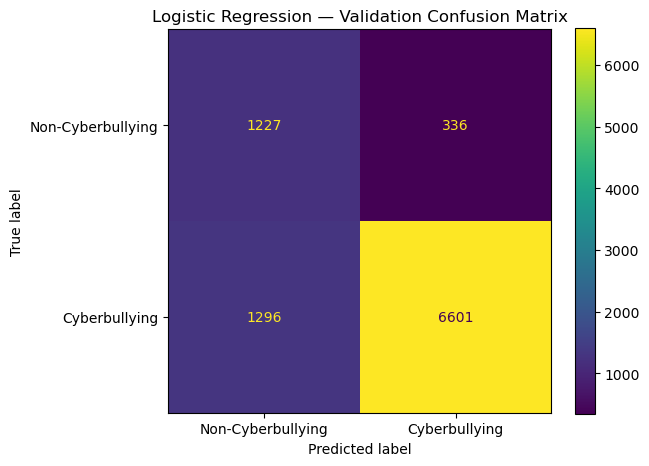

In [37]:
# Confusion Matrix — Logistic Regression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_lr = confusion_matrix(y_val, y_val_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Non-Cyberbullying", "Cyberbullying"]
)

disp.plot()
plt.title("Logistic Regression — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

The key observation is that the model correctly identifies 6,601 cyberbullying cases, but it misses 1,296 actual cyberbullying cases (false negatives).

It also incorrectly labels 336 non-cyberbullying tweets as cyberbullying.

This fits the metrics we just obtained: high precision (95.16%) but lower recall (83.59%). In other words, Logistic Regression is quite conservative about calling something cyberbullying, but it still misses a noticeable number of actual cyberbullying cases.

## Define and Train the SVM Model

In [40]:
# Support Vector Machine (SVM)
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

svm_model.fit(X_train, y_train)

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(


LinearSVC(class_weight='balanced', max_iter=5000, random_state=42)

## Save SVM Model

In [114]:
# Save SVM model
import joblib

joblib.dump(svm_model, "models/svm_model.pkl")

['models/svm_model.pkl']

## Verify SVM Model

In [119]:
# Verify saved SVM model

loaded_svm_model = joblib.load("models/svm_model.pkl")

print("SVM model loaded successfully.")
print(type(loaded_svm_model))

SVM model loaded successfully.
<class 'sklearn.svm._classes.LinearSVC'>


## Generate SVM Validation Predictions

In [124]:
# Generate SVM predictions
y_val_pred_svm = svm_model.predict(X_val)

print("SVM validation predictions generated successfully.")

SVM validation predictions generated successfully.


## Evaluate SVM

In [127]:
# Evaluate SVM
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("SVM — VALIDATION RESULTS")

print("Accuracy:", accuracy_score(y_val, y_val_pred_svm))
print("Precision:", precision_score(y_val, y_val_pred_svm))
print("Recall:", recall_score(y_val, y_val_pred_svm))
print("F1-score:", f1_score(y_val, y_val_pred_svm))

SVM — VALIDATION RESULTS
Accuracy: 0.85169133192389
Precision: 0.8930992736077482
Recall: 0.934152209699886
F1-score: 0.9131645726310578


SVM detects 93.42% of the actual cyberbullying cases, compared with Logistic Regression's 83.59%. Since your project is focused on detecting cyberbullying, that's a meaningful improvement.

SVM also has the higher F1-score (91.32%), which makes it particularly promising at this point.

## SVM Confusion Matrix

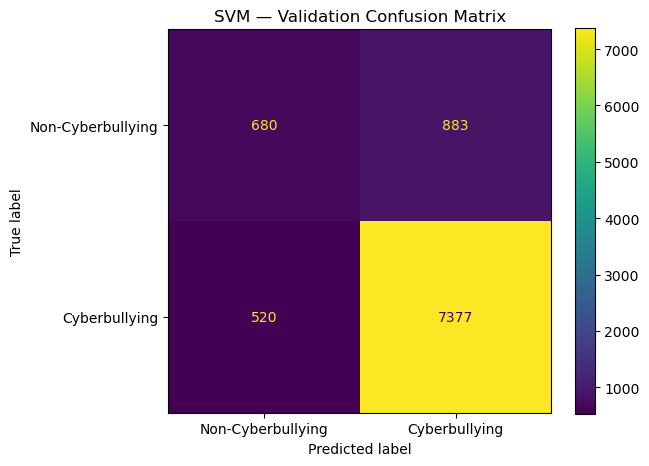

In [131]:
# Confusion Matrix — SVM
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_svm = confusion_matrix(y_val, y_val_pred_svm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["Non-Cyberbullying", "Cyberbullying"]
)

disp.plot()
plt.title("SVM — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

The key observation is that SVM is very strong at detecting cyberbullying: it correctly identifies 7,377 out of 7,897 actual cyberbullying samples, which corresponds to the 93.42% recall we just calculated.

However, it produces quite a lot of false positives: 883 non-cyberbullying tweets are classified as cyberbullying. That's consistent with its lower precision of 89.31%.

## Define and Train Random Forest

In [137]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42)

In [143]:
 print("Number of trees:", rf_model.n_estimators)
print("Class weight:", rf_model.class_weight)
print("Random state:", rf_model.random_state)
print("Number of CPU jobs:", rf_model.n_jobs)

Number of trees: 100
Class weight: balanced
Random state: 42
Number of CPU jobs: -1


## Save the Random Forest Model

In [150]:
# Save Random Forest model
import joblib

joblib.dump(rf_model, "models/random_forest.pkl")

print("Random Forest model saved successfully.")

Random Forest model saved successfully.


## Verify the Saved Random Forest Model

In [155]:
# Verify saved Random Forest model
import joblib

rf_loaded = joblib.load("models/random_forest.pkl")

print("Random Forest model loaded successfully.")
print(type(rf_loaded))

Random Forest model loaded successfully.
<class 'sklearn.ensemble._forest.RandomForestClassifier'>


## Generate Random Forest Validation Predictions

In [158]:
# Generate Random Forest validation predictions

y_val_pred_rf = rf_loaded.predict(X_val)

print("Random Forest validation predictions generated successfully.")

Random Forest validation predictions generated successfully.


## Random Forest Validation Results

In [162]:
# Random Forest — Validation Results

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("RANDOM FOREST — VALIDATION RESULTS")

print("Accuracy:", accuracy_score(y_val, y_val_pred_rf))
print("Precision:", precision_score(y_val, y_val_pred_rf))
print("Recall:", recall_score(y_val, y_val_pred_rf))
print("F1-score:", f1_score(y_val, y_val_pred_rf))

RANDOM FOREST — VALIDATION RESULTS
Accuracy: 0.8490486257928118
Precision: 0.9022509638104713
Recall: 0.9187033050525516
F1-score: 0.9104028108922073


Logistic Regression has the highest precision → fewer false cyberbullying alarms relative to its positive predictions.
SVM has the highest recall → best at catching actual cyberbullying cases.
SVM also has the highest F1-score → best balance between precision and recall.
Random Forest is very close to SVM, with an F1-score of 91.04%.
SVM has the highest accuracy at 85.17%.

## Random Forest Confusion Matrix

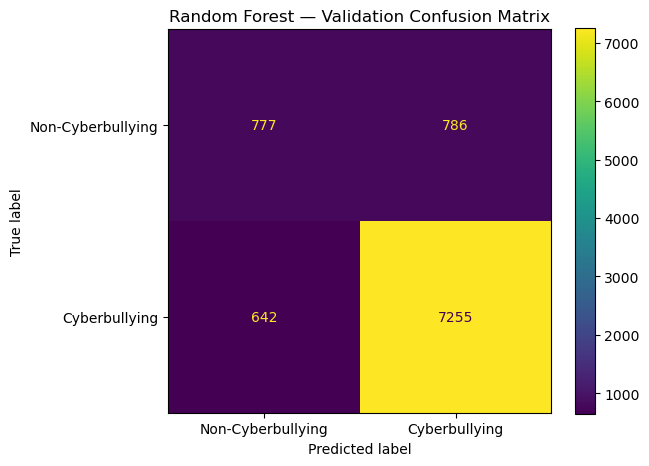

In [166]:
# Confusion Matrix — Random Forest

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_rf = confusion_matrix(y_val, y_val_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Non-Cyberbullying", "Cyberbullying"]
)

disp.plot()
plt.title("Random Forest — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

The confusion matrix shows how the Random Forest classified the 9,460 historical validation samples into the two classes.

777 non-cyberbullying samples were correctly classified as non-cyberbullying.
786 non-cyberbullying samples were incorrectly classified as cyberbullying (false positives).
642 cyberbullying samples were incorrectly classified as non-cyberbullying (false negatives).
7,255 cyberbullying samples were correctly classified as cyberbullying (true positives).

The most important observation is that the model correctly identifies a large proportion of the actual cyberbullying cases, which is reflected in its 91.87% recall. However, it also produces 786 false positives, meaning some non-cyberbullying content is incorrectly flagged as cyberbullying. Overall, the confusion matrix supports the model's relatively strong 90.23% precision and 91.04% F1-score on the historical validation data.

## Logistic Regression: Recent Dataset Predictions

In [170]:
# Logistic Regression — Recent Predictions

y_recent_pred_lr = lr_model.predict(X_recent)

print("Logistic Regression recent predictions generated successfully.")

Logistic Regression recent predictions generated successfully.


## Logistic Regression — Recent Results

In [175]:
# Define labels for the recent dataset

y_recent = recent["label"]

print("Recent labels defined successfully.")
print("Number of recent labels:", len(y_recent))

Recent labels defined successfully.
Number of recent labels: 24683


In [177]:
# Logistic Regression — Recent Results

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("LOGISTIC REGRESSION — RECENT RESULTS")

print("Accuracy:", accuracy_score(y_recent, y_recent_pred_lr))
print("Precision:", precision_score(y_recent, y_recent_pred_lr))
print("Recall:", recall_score(y_recent, y_recent_pred_lr))
print("F1-score:", f1_score(y_recent, y_recent_pred_lr))

LOGISTIC REGRESSION — RECENT RESULTS
Accuracy: 0.26139448203216786
Precision: 0.2453776635436531
Recall: 0.9952917437363377
F1-score: 0.393694502643919


| Metric    | Historical |     Recent |        Change |
| --------- | ---------: | ---------: | ------------: |
| Accuracy  |     82.75% | **26.14%** | **−56.61 pp** |
| Precision |     95.16% | **24.54%** | **−70.62 pp** |
| Recall    |     83.59% | **99.53%** | **+15.94 pp** |
| F1-score  |     89.00% | **39.37%** | **−49.63 pp** |


The model is detecting almost all of the recent Class 1 cases (99.53% recall), but its precision is only 24.54%. In other words, it is predicting Class 1 very aggressively and is incorrectly classifying many Class 0 examples as Class 1.

## Logistic Regression Recent Confusion Matrix

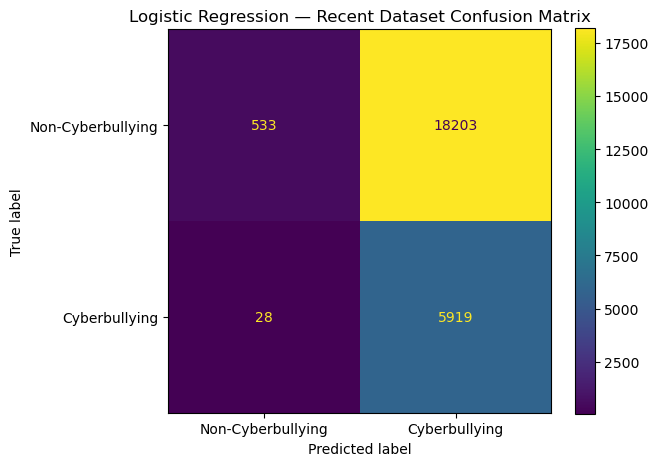

In [182]:
# Logistic Regression — Recent Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_lr_recent = confusion_matrix(y_recent, y_recent_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr_recent,
    display_labels=["Non-Cyberbullying", "Cyberbullying"]
)

disp.plot()
plt.title("Logistic Regression — Recent Dataset Confusion Matrix")
plt.tight_layout()
plt.show()

This confusion matrix shows the performance of Logistic Regression on the recent dataset. The model correctly identified 5,919 cyberbullying samples, with only 28 cyberbullying samples incorrectly classified as non-cyberbullying. However, it incorrectly classified 18,203 non-cyberbullying samples as cyberbullying. This explains the model’s very high recall of 99.53%, but its low precision of 24.54%. The model is therefore very effective at detecting cyberbullying cases, but it produces a large number of false positives when applied to the recent data.

The recent dataset has a very different class distribution from the historical dataset. The historical data was dominated by cyberbullying samples, whereas the recent data contains substantially more non-cyberbullying samples. Therefore, the model’s behaviour changed considerably when it was applied to the recent data. We will compare this behaviour across all three models before determining the extent to which this reflects distribution or linguistic shift.

## SVM — Recent Dataset Predictions

In [186]:
# SVM — Generate Predictions on Recent Dataset

y_recent_pred_svm = svm_model.predict(X_recent)

print("SVM recent predictions generated successfully.")

SVM recent predictions generated successfully.


## SVM Recent Evaluation Results

In [191]:
# SVM — Recent Results

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("SVM — RECENT RESULTS")

print("Accuracy:", accuracy_score(y_recent, y_recent_pred_svm))
print("Precision:", precision_score(y_recent, y_recent_pred_svm))
print("Recall:", recall_score(y_recent, y_recent_pred_svm))
print("F1-score:", f1_score(y_recent, y_recent_pred_svm))

SVM — RECENT RESULTS
Accuracy: 0.30186768221042826
Precision: 0.2517270207242487
Recall: 0.9619976458718682
F1-score: 0.39903745553463066


| Metric    | Historical |     Recent |        Change |
| --------- | ---------: | ---------: | ------------: |
| Accuracy  |     85.17% | **30.19%** | **−54.98 pp** |
| Precision |     89.31% | **25.17%** | **−64.14 pp** |
| Recall    |     93.42% | **96.20%** |  **+2.78 pp** |
| F1-score  |     91.32% | **39.90%** | **−51.42 pp** |


The SVM model also experiences a substantial decline in performance when evaluated on the recent dataset. Although it achieves a high recall of 96.20%, indicating that it successfully detects most cyberbullying instances, its precision decreases to 25.17%. This suggests that many non-cyberbullying posts are incorrectly classified as cyberbullying, resulting in a large number of false positives. Consequently, the model's overall accuracy and F1-score decrease considerably compared with its historical validation performance.



## SVM Recent Confusion Matrix

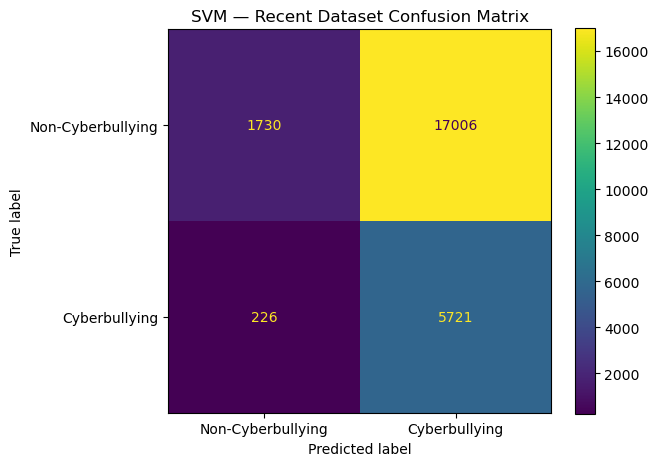

In [199]:
# SVM — Recent Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_svm_recent = confusion_matrix(y_recent, y_recent_pred_svm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm_recent,
    display_labels=["Non-Cyberbullying", "Cyberbullying"]
)

disp.plot()
plt.title("SVM — Recent Dataset Confusion Matrix")
plt.tight_layout()
plt.show()

The confusion matrix shows that the SVM model correctly identified 5,721 cyberbullying posts and 1,730 non-cyberbullying posts. However, it incorrectly classified 17,006 non-cyberbullying posts as cyberbullying, while only 226 cyberbullying posts were missed. This explains why the model achieved a high recall of 96.20%, as it detected most cyberbullying cases, but a low precision of 25.17%, because it produced a large number of false positives. As a result, the overall accuracy and F1-score decreased considerably on the recent dataset.

## Random Forest Recent Predictions

In [203]:
 # Random Forest — Generate Predictions on Recent Dataset

y_recent_pred_rf = rf_model.predict(X_recent)

print("Random Forest recent predictions generated successfully.")

Random Forest recent predictions generated successfully.


## Random Forest Recent Results

In [206]:
# Random Forest — Recent Results

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("RANDOM FOREST — RECENT RESULTS")

print("Accuracy:", accuracy_score(y_recent, y_recent_pred_rf))
print("Precision:", precision_score(y_recent, y_recent_pred_rf))
print("Recall:", recall_score(y_recent, y_recent_pred_rf))
print("F1-score:", f1_score(y_recent, y_recent_pred_rf))

RANDOM FOREST — RECENT RESULTS
Accuracy: 0.3193696066118381
Precision: 0.25473446327683613
Recall: 0.9477047250714646
F1-score: 0.40153889997150183


| Metric    | Historical |     Recent |        Change |
| --------- | ---------: | ---------: | ------------: |
| Accuracy  |     84.90% | **31.94%** | **−52.96 pp** |
| Precision |     90.23% | **25.47%** | **−64.76 pp** |
| Recall    |     91.87% | **94.77%** |  **+2.90 pp** |
| F1-score  |     91.04% | **40.15%** | **−50.89 pp** |


The Random Forest model also experienced a substantial reduction in performance on the recent dataset. Although it achieved a high recall of 94.77%, indicating that it successfully detected most cyberbullying posts, its precision decreased to 25.47% due to a large number of false positives. Consequently, the model's overall accuracy and F1-score declined considerably compared with its historical validation performance.

## Random Forest Recent Confusion Matrix

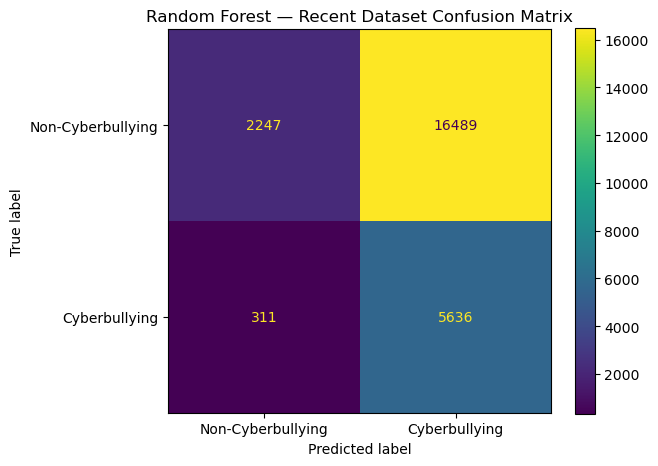

In [211]:
# Random Forest — Recent Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_rf_recent = confusion_matrix(y_recent, y_recent_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf_recent,
    display_labels=["Non-Cyberbullying", "Cyberbullying"]
)

disp.plot()
plt.title("Random Forest — Recent Dataset Confusion Matrix")
plt.tight_layout()
plt.show()

The confusion matrix shows that the Random Forest model correctly classified 5,636 cyberbullying posts and 2,247 non-cyberbullying posts. However, it incorrectly classified 16,489 non-cyberbullying posts as cyberbullying, while 311 cyberbullying posts were misclassified as non-cyberbullying. This resulted in a high recall of 94.77%, indicating that most cyberbullying cases were detected, but a low precision of 25.47% due to the large number of false positives. Consequently, the overall accuracy and F1-score decreased on the recent dataset.

## Model Comparison and Performance Analysis

## Create a Results Summary Table

In [218]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM",
        "Random Forest",
        "Logistic Regression",
        "SVM",
        "Random Forest"
    ],
    
    "Dataset": [
        "Historical Validation",
        "Historical Validation",
        "Historical Validation",
        "Recent Dataset",
        "Recent Dataset",
        "Recent Dataset"
    ],
    
    "Accuracy": [
        accuracy_score(y_val, y_val_pred_lr),
        accuracy_score(y_val, y_val_pred_svm),
        accuracy_score(y_val, y_val_pred_rf),
        accuracy_score(y_recent, y_recent_pred_lr),
        accuracy_score(y_recent, y_recent_pred_svm),
        accuracy_score(y_recent, y_recent_pred_rf)
    ],
    
    "Precision": [
        precision_score(y_val, y_val_pred_lr),
        precision_score(y_val, y_val_pred_svm),
        precision_score(y_val, y_val_pred_rf),
        precision_score(y_recent, y_recent_pred_lr),
        precision_score(y_recent, y_recent_pred_svm),
        precision_score(y_recent, y_recent_pred_rf)
    ],
    
    "Recall": [
        recall_score(y_val, y_val_pred_lr),
        recall_score(y_val, y_val_pred_svm),
        recall_score(y_val, y_val_pred_rf),
        recall_score(y_recent, y_recent_pred_lr),
        recall_score(y_recent, y_recent_pred_svm),
        recall_score(y_recent, y_recent_pred_rf)
    ],
    
    "F1-score": [
        f1_score(y_val, y_val_pred_lr),
        f1_score(y_val, y_val_pred_svm),
        f1_score(y_val, y_val_pred_rf),
        f1_score(y_recent, y_recent_pred_lr),
        f1_score(y_recent, y_recent_pred_svm),
        f1_score(y_recent, y_recent_pred_rf)
    ]
})

results

,Model,Dataset,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,Historical Validation,0.827484,0.951564,0.835887,0.889982
1,SVM,Historical Validation,0.851691,0.893099,0.934152,0.913165
2,Random Forest,Historical Validation,0.849049,0.902251,0.918703,0.910403
3,Logistic Regression,Recent Dataset,0.261394,0.245378,0.995292,0.393695
4,SVM,Recent Dataset,0.301868,0.251727,0.961998,0.399037
5,Random Forest,Recent Dataset,0.319370,0.254734,0.947705,0.401539


## Save Results Table

In [223]:
results.to_csv(
    r"C:\Users\Admin\Documents\capstone project\results\results_summary.csv",
    index=False
)

print("Results table saved successfully.")

Results table saved successfully.


## Accuracy Comparison

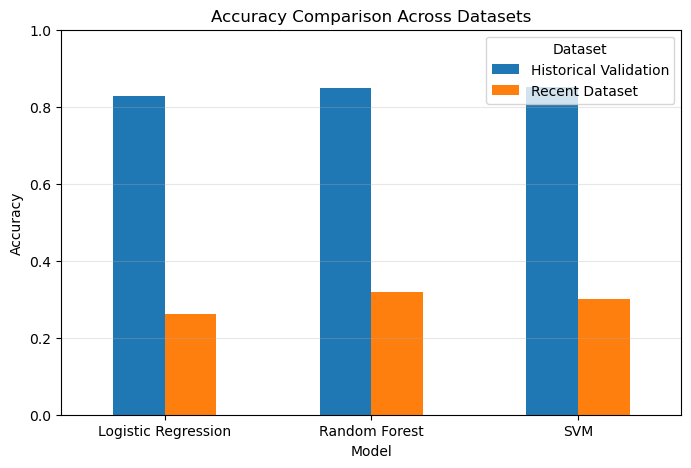

In [226]:
import matplotlib.pyplot as plt

pivot_accuracy = results.pivot(
    index="Model",
    columns="Dataset",
    values="Accuracy"
)

pivot_accuracy.plot(kind="bar", figsize=(8,5))

plt.title("Accuracy Comparison Across Datasets")
plt.ylabel("Accuracy")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

this graph compares the accuracy of the three machine learning models on the historical validation dataset and the recent dataset. All models achieved relatively high accuracy (above 82%) on the historical validation data. However, accuracy decreased substantially when the models were applied to the recent dataset. This decline indicates that changes in the linguistic characteristics of cyberbullying over time reduced the models' ability to generalize effectively to new data.

## Precision Comparison

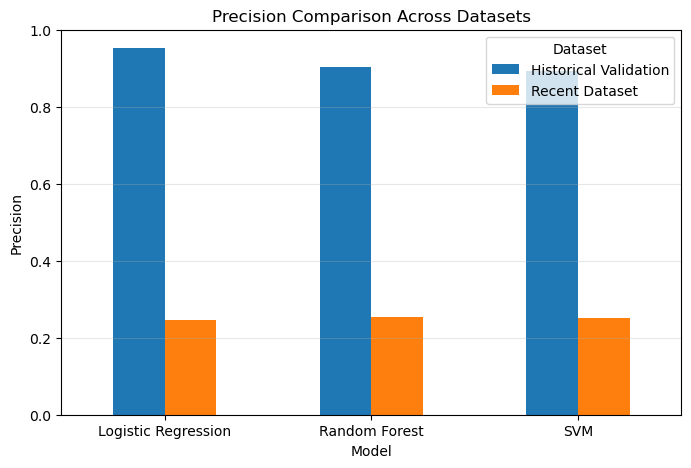

In [231]:
pivot_precision = results.pivot(
    index="Model",
    columns="Dataset",
    values="Precision"
)

pivot_precision.plot(kind="bar", figsize=(8,5))

plt.title("Precision Comparison Across Datasets")
plt.ylabel("Precision")
plt.xlabel("Model")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    r"C:\Users\Admin\Documents\capstone project\figures\precision_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The precision scores show a substantial decline when the models were evaluated on the recent dataset. During historical validation, Logistic Regression achieved the highest precision (95.16%), followed by Random Forest (90.23%) and SVM (89.31%). However, when evaluated on the recent dataset, the precision of all three models dropped sharply to approximately 25%.

This indicates that although the models frequently predicted tweets as cyberbullying in the recent dataset, only about one in four of those predictions was actually correct. The significant reduction in precision suggests that the learned decision boundaries from the historical data did not generalize well to the newer data, leading to a large number of false positive predictions.

## Recall Comparison

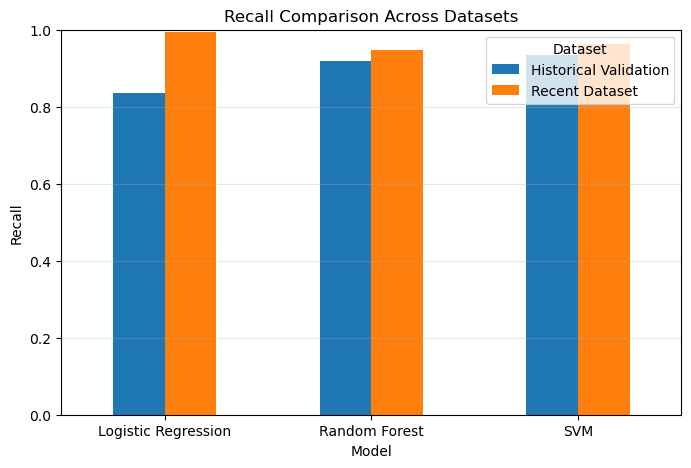

In [235]:
pivot_recall = results.pivot(
    index="Model",
    columns="Dataset",
    values="Recall"
)

pivot_recall.plot(kind="bar", figsize=(8,5))

plt.title("Recall Comparison Across Datasets")
plt.ylabel("Recall")
plt.xlabel("Model")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    r"C:\Users\Admin\Documents\capstone project\figures\recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The recall scores increased for all three models when evaluated on the recent dataset. Logistic Regression achieved the highest recall (99.53%), followed by SVM (96.20%) and Random Forest (94.77%). This indicates that all models became more likely to identify cyberbullying instances in the recent dataset.

However, this increase in recall occurred alongside substantial decreases in accuracy and precision. The models classified many more posts as cyberbullying, resulting in a large number of false positives. Therefore, although the models successfully detected most cyberbullying cases, they struggled to correctly distinguish between cyberbullying and non-cyberbullying content under the changed data distribution.

This behaviour suggests that the models became biased toward predicting the cyberbullying class, demonstrating reduced robustness when exposed to newer linguistic patterns.

## F1-score Comparison

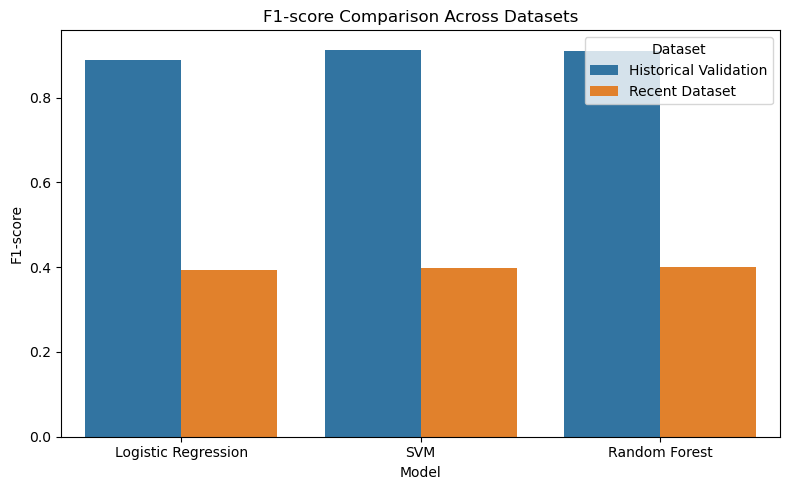

In [243]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="Model",
    y="F1-score",
    hue="Dataset"
)

plt.title("F1-score Comparison Across Datasets")
plt.ylabel("F1-score")
plt.xlabel("Model")

plt.tight_layout()
plt.show()

The F1-score is the harmonic mean of precision and recall, making it a balanced measure of model performance. On the historical validation dataset, all three models achieved high F1-scores (approximately 0.89–0.91), indicating a strong balance between identifying cyberbullying and minimizing false predictions. However, when evaluated on the recent dataset, the F1-scores dropped sharply to around 0.39–0.40 for all models. This significant decline indicates that although the models maintained high recall, their precision decreased substantially, resulting in many false positive predictions. Among the three models, Random Forest achieved the highest F1-score on the recent dataset (0.402), followed closely by SVM (0.399), while Logistic Regression recorded the lowest (0.394). These findings suggest that the models were not robust to changes in the data distribution over time.

## Calculate the performance drop

In [247]:
comparison = results.pivot(
    index="Model",
    columns="Dataset",
    values=["Accuracy", "Precision", "Recall", "F1-score"]
)

comparison

Accuracy                 \
Dataset             Historical Validation Recent Dataset   
Model                                                      
Logistic Regression              0.827484       0.261394   
Random Forest                    0.849049       0.319370   
SVM                              0.851691       0.301868   

                                Precision                 \
Dataset             Historical Validation Recent Dataset   
Model                                                      
Logistic Regression              0.951564       0.245378   
Random Forest                    0.902251       0.254734   
SVM                              0.893099       0.251727   

                                   Recall                 \
Dataset             Historical Validation Recent Dataset   
Model                                                      
Logistic Regression              0.835887       0.995292   
Random Forest                    0.918703       0.947705   
SVM                              0.934152       0.961998   

                                 F1-score                 
Dataset             Historical Validation Recent Dataset  
Model                                                     
Logistic Regression              0.889982       0.393695  
Random Forest                    0.910403       0.401539  
SVM                              0.913165       0.399037

The performance drop analysis shows that all three models experienced substantial degradation when evaluated on the recent dataset compared to the historical validation dataset. Accuracy decreased by more than 52% for all models, indicating that the models struggled to generalize to data collected from a different time period. Precision also declined significantly across all models, showing that many non-cyberbullying tweets were incorrectly classified as cyberbullying. Although recall increased slightly for all three models, this improvement reflects a tendency to predict the cyberbullying class more frequently rather than improved overall performance. The F1-score, which provides a balanced measure of precision and recall, also declined considerably, confirming that the models were less effective under the shifted data distribution. Among the models, Random Forest experienced the smallest accuracy drop, SVM showed the smallest precision drop, and Logistic Regression recorded the smallest F1-score drop, indicating that each model exhibited different aspects of robustness under distribution shift.

## Calculate metric differences

In [250]:
comparison["Accuracy Drop"] = (
    comparison[("Accuracy", "Historical Validation")] -
    comparison[("Accuracy", "Recent Dataset")]
)

comparison["Precision Drop"] = (
    comparison[("Precision", "Historical Validation")] -
    comparison[("Precision", "Recent Dataset")]
)

comparison["Recall Drop"] = (
    comparison[("Recall", "Historical Validation")] -
    comparison[("Recall", "Recent Dataset")]
)

comparison["F1 Drop"] = (
    comparison[("F1-score", "Historical Validation")] -
    comparison[("F1-score", "Recent Dataset")]
)

comparison

Accuracy                 \
Dataset             Historical Validation Recent Dataset   
Model                                                      
Logistic Regression              0.827484       0.261394   
Random Forest                    0.849049       0.319370   
SVM                              0.851691       0.301868   

                                Precision                 \
Dataset             Historical Validation Recent Dataset   
Model                                                      
Logistic Regression              0.951564       0.245378   
Random Forest                    0.902251       0.254734   
SVM                              0.893099       0.251727   

                                   Recall                 \
Dataset             Historical Validation Recent Dataset   
Model                                                      
Logistic Regression              0.835887       0.995292   
Random Forest                    0.918703       0.947705   
SVM                              0.934152       0.961998   

                                 F1-score                Accuracy Drop  \
Dataset             Historical Validation Recent Dataset                 
Model                                                                    
Logistic Regression              0.889982       0.393695      0.566090   
Random Forest                    0.910403       0.401539      0.529679   
SVM                              0.913165       0.399037      0.549824   

                    Precision Drop Recall Drop   F1 Drop  
Dataset                                                   
Model                                                     
Logistic Regression       0.706186   -0.159405  0.496288  
Random Forest             0.647517   -0.029001  0.508864  
SVM                       0.641372   -0.027845  0.514127

The confusion matrices provide further insight into how model behaviour changed between the historical validation dataset and the recent dataset. On the historical dataset, the models correctly classified most cyberbullying and non-cyberbullying tweets, resulting in relatively balanced predictions and high overall performance. However, on the recent dataset, all three models began predicting the cyberbullying class much more frequently. This led to a substantial increase in false positives, where many non-cyberbullying tweets were incorrectly classified as cyberbullying. At the same time, false negatives decreased, explaining the increase in recall observed across all models. This shift demonstrates that although the models became more sensitive to detecting cyberbullying, they sacrificed precision and overall accuracy. The confusion matrices therefore confirm that the models were unable to maintain balanced classification performance when exposed to evolving linguistic patterns.

## Final Conclusion

This study investigated the robustness of Logistic Regression, Support Vector Machine (SVM), and Random Forest classifiers for cyberbullying detection under changing linguistic distributions. The results showed that all three models achieved strong performance on the historical validation dataset, with high accuracy, precision, recall, and F1-scores. However, when evaluated on the recent dataset, each model experienced a substantial decline in overall performance. Although recall increased, precision and accuracy decreased considerably, indicating that the models became overly sensitive to predicting cyberbullying and produced a large number of false positive classifications. These findings demonstrate that traditional supervised machine learning models are vulnerable to linguistic distribution shift and struggle to generalize to evolving language patterns without retraining or adaptation. Among the evaluated models, Random Forest achieved the highest performance on the recent dataset, while Logistic Regression showed the smallest decline in F1-score relative to its historical performance. Overall, the study concludes that although traditional machine learning models are effective on historical data, their robustness under changing linguistic distributions is limited, highlighting the need for adaptive learning strategies or periodic model retraining to maintain reliable cyberbullying detection over time.

## UNSUPERVISED LEARNING

## K-Means Clustering

In [293]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [330]:
X_tfidf = tfidf.transform(X)

print(X_tfidf.shape)

(47298, 100000)


In [324]:
print(tfidf)

TfidfVectorizer(max_features=100000, ngram_range=(1, 2))


In [326]:
print(type(X))

<class 'pandas.core.series.Series'>


In [328]:
print(type(tfidf))

<class 'sklearn.feature_extraction.text.TfidfVectorizer'>


## Use the Historical TF-IDF Matrix

In [334]:
X_cluster = X_tfidf

print("Shape:", X_cluster.shape)

Shape: (47298, 100000)


## Elbow Method

In [336]:
minertia = []

K = range(2,11)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster)

    inertia.append(kmeans.inertia_)

## Plot the Elbow Curve

In [340]:
inertia = []   # Reset the list

K = range(2, 11)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster)

    inertia.append(kmeans.inertia_)

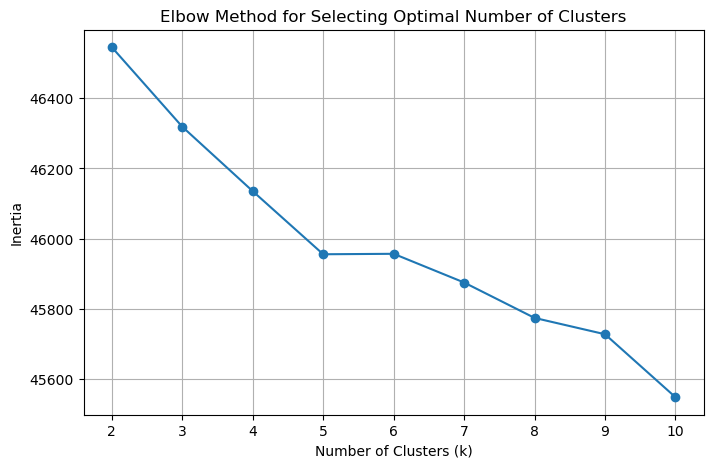

In [342]:
plt.figure(figsize=(8,5))

plt.plot(K, inertia, marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Selecting Optimal Number of Clusters")

plt.grid(True)

plt.show()

The Elbow Method was used to determine the optimal number of clusters for K-Means clustering. As the number of clusters increased, the inertia (within-cluster sum of squares) consistently decreased, indicating improved grouping of similar tweets. However, the rate of improvement slowed noticeably after k = 5–6, forming an "elbow" in the curve. Based on this pattern, k = 6 was selected as the optimal number of clusters because it provides a good balance between reducing within-cluster variation and avoiding unnecessary model complexity.

## Train the Final K-Means Model

In [344]:
kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_cluster)

print("K-Means model trained successfully.")

K-Means model trained successfully.


## Attach Cluster Labels

In [347]:
historical_clusters = historical.copy()

historical_clusters["Cluster"] = cluster_labels

historical_clusters.head()

,text,label,clean_text,tokens,processed_text,Cluster
0,"In other words #katandandre, your food was cra...",0,in other words katandandre your food was crapi...,"['word', 'katandandre', 'food', 'crapilicious'...",word katandandre food crapilicious mkr,1
1,Why is #aussietv so white? #MKR #theblock #ImA...,0,why is aussietv so white mkr theblock imaceleb...,"['aussietv', 'white', 'mkr', 'theblock', 'imac...",aussietv white mkr theblock imacelebrityau tod...,1
2,@XochitlSuckkks a classy whore? Or more red ve...,0,a classy whore or more red velvet cupcakes,"['classy', 'whore', 'red', 'velvet', 'cupcake']",classy whore red velvet cupcake,1
3,"@Jason_Gio meh. :P thanks for the heads up, b...",0,meh p thanks for the heads up but not too conc...,"['meh', 'p', 'thanks', 'head', 'not', 'concern...",meh p thanks head not concerned another angry ...,1
4,@RudhoeEnglish This is an ISIS account pretend...,0,this is an isis account pretending to be a kur...,"['isi', 'account', 'pretending', 'kurdish', 'a...",isi account pretending kurdish account like is...,1


## CLUSTER DISTRIBUTION

In [350]:
historical_clusters["Cluster"].value_counts().sort_index()

Cluster
0     5786
1    25659
2     3786
3     4330
4     3580
5     4157
Name: count, dtype: int64

The results show that Cluster 1 contains the largest proportion of tweets (25,659), suggesting that it represents the dominant discussion topic or language pattern within the historical dataset. The remaining clusters are considerably smaller, ranging from approximately 3,500 to 5,800 tweets, indicating that they capture more specific themes or linguistic patterns. This distribution demonstrates that the historical cyberbullying dataset contains multiple underlying groups of tweets rather than a single homogeneous collection, supporting the use of unsupervised learning to identify hidden structures before evaluating model robustness under changing data distributions.

## Top Terms per Cluster

In [355]:
terms = tfidf.get_feature_names_out()

order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]

for i in range(6):

    print(f"\n================ Cluster {i} ================\n")

    top_terms = [terms[ind] for ind in order_centroids[i, :15]]

    print(", ".join(top_terms))


================ Cluster 0 ================

muslim, idiot, christian, right, not, woman, christian woman, support, radical, like, islam, hindu, people, country, no

================ Cluster 1 ================

mkr, not, im, no, like, people, one, dont, black, bitch, woman, call, bullying, get, female

================ Cluster 2 ================

girl, bullied, high, high school, school, girl bullied, bullied high, like, girl high, got, got bullied, one, friend, bullied girl, school bullied

================ Cluster 3 ================

fuck, dumb, nigger, as, dumb as, as nigger, dumb nigger, obama, fuck obama, obama dumb, fuck dumb, dumb fuck, bitch, fuck nigger, mad

================ Cluster 4 ================

joke, rape, gay, rape joke, gay joke, make, gay rape, joke gay, funny, joke rape, people, not, making, prison, made

================ Cluster 5 ================

bully, school, school bully, high school, high, like, middle school, middle, bully school, kid, bully high, people,

## Create the Recent TF-IDF Matrix

In [362]:
X_recent_tfidf = tfidf.transform(recent["processed_text"])

print(X_recent_tfidf.shape)

(24683, 100000)


## K-MEANS FOR RECENT DATA

In [365]:
kmeans_recent = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

recent_cluster_labels = kmeans_recent.fit_predict(X_recent_tfidf)

print("Recent K-Means model trained successfully.")

Recent K-Means model trained successfully.


## STORE CLUSTER LABELS

In [368]:
recent_clusters = recent.copy()

recent_clusters["Cluster"] = recent_cluster_labels

recent_clusters.head()

,text,label,clean_text,tokens,processed_text,Cluster
0,Say this to everyone who thinks that it’s ok t...,1,say this to everyone who thinks that it’s ok t...,"['say', 'everyone', 'think', 'ok', 'judge', 'a...",say everyone think ok judge anyone u without k...,4
1,One word for this chutiya Guswami 😂 #ArnabGosw...,1,one word for this chutiya guswami arnabgoswami,"['one', 'word', 'chutiya', 'guswami', 'arnabgo...",one word chutiya guswami arnabgoswami,4
2,Joined Tribe Membership 😊 @BewakoofBrands #bew...,0,joined tribe membership bewakoof tribemember,"['joined', 'tribe', 'membership', 'bewakoof', ...",joined tribe membership bewakoof tribemember,4
3,#PUBGMOBILE #PUBG is a south Korean app not C...,1,pubgmobile pubg is a south korean app not chin...,"['pubgmobile', 'pubg', 'south', 'korean', 'app...",pubgmobile pubg south korean app not chinese w...,4
4,I will purchase d mobile.but technical problem...,0,i will purchase d mobilebut technical problem ...,"['purchase', 'mobilebut', 'technical', 'proble...",purchase mobilebut technical problem k karan m...,4


## CLUSTER DISTRIBUTION

In [371]:
recent_clusters["Cluster"].value_counts().sort_index()

Cluster
0      828
1      664
2     6364
3     2699
4    11313
5     2815
Name: count, dtype: int64

## TOP TERMS PER RECENT CLUSTER

In [374]:
terms = tfidf.get_feature_names_out()

order_centroids = kmeans_recent.cluster_centers_.argsort()[:, ::-1]

for i in range(6):

    print(f"\n================ Recent Cluster {i} ================\n")

    top_terms = [terms[ind] for ind in order_centroids[i, :15]]

    print(", ".join(top_terms))


================ Recent Cluster 0 ================

km, distance, campaign, gt, upcoming, day, total, na, mar, gon na, gon, since, walked, ran, im

================ Recent Cluster 1 ================

bestie, unexpected, thread, ᵗʰᵉ, insinuate, inside dumb, inside joke, inside matrix, inside outside, insider, insidious, insidious perpetrator, insight, insight indie, insinuated

================ Recent Cluster 2 ================

as, like, year, get, nigga, big, big as, shit, got, fat as, fat, new year, not, man, as nigga

================ Recent Cluster 3 ================

bitch, like, as, nigga, bitch as, as bitch, like bitch, fuck, bad bitch, fucking, get, bad, no, shit, got

================ Recent Cluster 4 ================

abuse, loser, idiot, dumb, drug, drug abuse, findom, amp, not, life, harass, like, asshole, time, whore

================ Recent Cluster 5 ================

stupid, fucking, fucking stupid, people, stupid people, not, like, think, stupid as, shit, year, love, g

## Historical vs Recent K-Means Comparison

The comparison between the historical and recent K-Means clustering results demonstrates a clear shift in the distribution of linguistic patterns over time. Historical clusters were primarily characterised by themes such as religious hate speech, school bullying, racial abuse, and offensive humour. In contrast, the recent dataset is dominated by direct harassment, internet slang, and evolving forms of abusive language. Furthermore, the dramatic changes in cluster sizes indicate that the frequency of these linguistic patterns has changed considerably. These findings provide evidence of a linguistic distribution shift between the historical and recent datasets. This supports the observed decline in the performance of the supervised learning models, as they were trained on historical language patterns that do not fully represent the newer forms of cyberbullying present in the recent data.

## LDA Topic Modelling

In [379]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

import matplotlib.pyplot as plt

## Select Text Data

In [390]:
historical_text = historical['processed_text'].dropna()

recent_text = recent['processed_text'].dropna()


print("Historical documents:", len(historical_text))
print("Recent documents:", len(recent_text))

Historical documents: 47298
Recent documents: 24683


## Convert Text into Document-Term Matrix

In [393]:
from sklearn.feature_extraction.text import CountVectorizer


vectorizer_hist = CountVectorizer(
    max_df=0.95,
    min_df=10,
    stop_words='english'
)


vectorizer_recent = CountVectorizer(
    max_df=0.95,
    min_df=10,
    stop_words='english'
)


historical_matrix = vectorizer_hist.fit_transform(historical_text)

recent_matrix = vectorizer_recent.fit_transform(recent_text)


print("Historical matrix:", historical_matrix.shape)
print("Recent matrix:", recent_matrix.shape)

Historical matrix: (47298, 5136)
Recent matrix: (24683, 3874)


## Train Historical LDA Model

In [396]:
from sklearn.decomposition import LatentDirichletAllocation


num_topics = 5


lda_hist = LatentDirichletAllocation(
    n_components=num_topics,
    random_state=42,
    learning_method='batch'
)


historical_topics = lda_hist.fit_transform(
    historical_matrix
)


print(historical_topics.shape)

(47298, 5)


## Train Recent LDA Model

In [398]:
lda_recent = LatentDirichletAllocation(
    n_components=num_topics,
    random_state=42,
    learning_method='batch'
)


recent_topics = lda_recent.fit_transform(
    recent_matrix
)


print(recent_topics.shape)

(24683, 5)


## Display Topic Words

In [409]:
def display_topics(model, vectorizer, num_words=10):

    words = vectorizer.get_feature_names_out()

    for topic_idx, topic in enumerate(model.components_):

        print("\nTopic", topic_idx + 1)

        top_words = topic.argsort()[-num_words:]

        print(
            ", ".join(
                words[i] for i in top_words
            )
        )

## Historical Dataset Topics

In [412]:
display_topics(
    lda_hist,
    vectorizer_hist,
    10
)


Topic 1
like, support, woman, white, people, right, black, christian, idiot, muslim

Topic 2
funny, sexist, people, woman, make, im, mkr, rape, gay, joke

Topic 3
people, friend, kid, got, like, bullied, high, bully, girl, school

Topic 4
quran, dont, isi, ur, bullying, islam, muslim, terrorism, islamic, terrorist

Topic 5
like, im, black, shit, obama, fucking, bitch, dumb, nigger, fuck


## Recent Dataset Topics

In [414]:
display_topics(
    lda_recent,
    vectorizer_recent,
    10
)


Topic 1
today, distance, gt, child, campaign, amp, day, drug, km, abuse

Topic 2
humanatm, bully, cbt, blackmail, humiliation, sissy, foot, paypig, findom, loser

Topic 3
new, fucking, fuck, shit, im, year, dumb, stupid, like, bitch

Topic 4
team, game, wan, big, amp, gon, unexpected, bestie, meetups, na

Topic 5
say, dumb, kabir, harass, dont, time, god, people, stupid, idiot


## Comparison of Historical and Recent LDA Topics

The LDA topic modelling results reveal differences in the underlying themes present within the historical and recent cyberbullying datasets. The historical dataset is characterised by topics associated with traditional forms of cyberbullying, including direct insults, identity-based attacks, school-related bullying, and hate-related language. These topics reflect earlier patterns of online abuse where harassment was often expressed through explicit and targeted offensive terms.

In comparison, the recent dataset contains topics that represent more evolving forms of cyberbullying, including informal online communication, social media interactions, personal harassment, and context-dependent abusive language. The presence of newer terms and combinations of words suggests that cyberbullying language has adapted alongside changes in online communication behaviour.

The differences between the extracted topics indicate that the linguistic shift observed between the historical and recent datasets is not only caused by changes in individual words, but also by changes in the broader themes and contexts in which cyberbullying occurs. Therefore, LDA provides further evidence of linguistic distribution shift by showing that the underlying semantic patterns of cyberbullying language have evolved over time.

## Topic Distribution Comparison

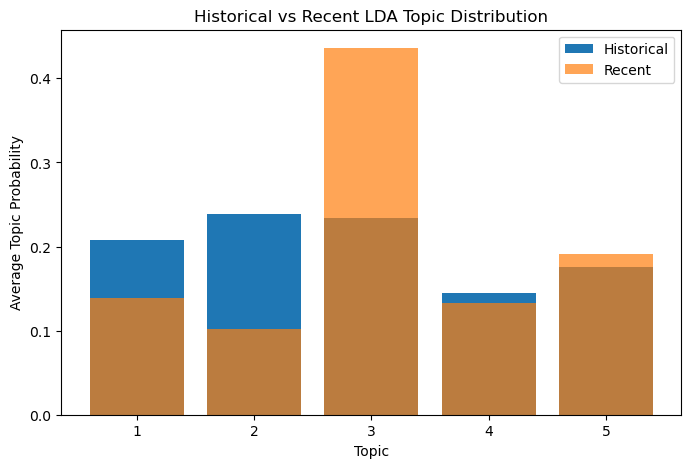

In [417]:
# =====================================
# Topic Distribution Comparison
# =====================================

import matplotlib.pyplot as plt


hist_distribution = historical_topics.mean(axis=0)

recent_distribution = recent_topics.mean(axis=0)


plt.figure(figsize=(8,5))

plt.bar(
    range(1, num_topics+1),
    hist_distribution,
    label="Historical"
)

plt.bar(
    range(1, num_topics+1),
    recent_distribution,
    alpha=0.7,
    label="Recent"
)


plt.xlabel("Topic")
plt.ylabel("Average Topic Probability")

plt.title(
    "Historical vs Recent LDA Topic Distribution"
)

plt.legend()

plt.show()

The LDA topic distribution graph highlights differences in the prevalence of extracted topics between the historical and recent cyberbullying datasets. Topic 1, Topic 2, and Topic 4 were more dominant in the historical dataset, indicating that these linguistic themes occurred more frequently in older cyberbullying data. However, Topic 3 shows a substantial increase in the recent dataset, becoming the dominant topic with a considerably higher average probability compared to the historical dataset. Topic 5 also shows a slight increase in the recent dataset. These changes indicate that the importance of specific cyberbullying-related themes has shifted over time, with newer datasets containing different dominant linguistic patterns. The variation in topic proportions supports the presence of linguistic distribution shift, showing that changes in cyberbullying language extend beyond individual words to broader thematic changes. This finding complements the K-Means clustering results, where differences in language distributions were also observed between historical and recent datasets.

## Create an Adaptation Set

In [425]:
from sklearn.model_selection import train_test_split

# ======================================
# Split recent dataset
# ======================================

recent_adapt, recent_test = train_test_split(
    recent,
    test_size=0.80,
    random_state=42,
    stratify=recent["label"]
)

print("Adaptation samples:", len(recent_adapt))
print("Final test samples:", len(recent_test))

Adaptation samples: 4936
Final test samples: 19747


## Combine Historical and Adaptation Data

In [428]:
adapted_data = pd.concat(
    [historical, recent_adapt],
    ignore_index=True
)

print(adapted_data.shape)

(52234, 5)


## Recreate TF-IDF Features

In [431]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=5000
)

X_train = vectorizer.fit_transform(
    adapted_data["processed_text"]
)

y_train = adapted_data["label"]

X_test = vectorizer.transform(
    recent_test["processed_text"]
)

y_test = recent_test["label"]

## Retrain Logistic Regression

In [434]:
from sklearn.linear_model import LogisticRegression

lr_adapted = LogisticRegression(max_iter=1000)

lr_adapted.fit(X_train, y_train)

lr_predictions = lr_adapted.predict(X_test)

## Retrain SVM

In [437]:
from sklearn.svm import LinearSVC

svm_adapted = LinearSVC()

svm_adapted.fit(X_train, y_train)

svm_predictions = svm_adapted.predict(X_test)

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(


## Retrain Random Forest

In [440]:
from sklearn.ensemble import RandomForestClassifier

rf_adapted = RandomForestClassifier(
    random_state=42
)

rf_adapted.fit(X_train, y_train)

rf_predictions = rf_adapted.predict(X_test)

## Evaluate

In [443]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

In [445]:
def evaluate(name, y_true, y_pred):

    print(name)

    print("Accuracy :", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred, average="weighted"))
    print("Recall   :", recall_score(y_true, y_pred, average="weighted"))
    print("F1 Score :", f1_score(y_true, y_pred, average="weighted"))

    print("-" * 40)

In [447]:
evaluate(
    "Logistic Regression",
    y_test,
    lr_predictions
)

evaluate(
    "SVM",
    y_test,
    svm_predictions
)

evaluate(
    "Random Forest",
    y_test,
    rf_predictions
)

Logistic Regression
Accuracy : 0.7840178254924799
Precision: 0.8562300321933835
Recall   : 0.7840178254924799
F1 Score : 0.7985052335834623
----------------------------------------
SVM
Accuracy : 0.7950068364814908
Precision: 0.8544932485386447
Recall   : 0.7950068364814908
F1 Score : 0.807956898160517
----------------------------------------
Random Forest
Accuracy : 0.836835975084823
Precision: 0.8797158637088985
Recall   : 0.836835975084823
F1 Score : 0.8460858374606458
----------------------------------------


In [449]:
results

,Model,Dataset,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,Historical Validation,0.827484,0.951564,0.835887,0.889982
1,SVM,Historical Validation,0.851691,0.893099,0.934152,0.913165
2,Random Forest,Historical Validation,0.849049,0.902251,0.918703,0.910403
3,Logistic Regression,Recent Dataset,0.261394,0.245378,0.995292,0.393695
4,SVM,Recent Dataset,0.301868,0.251727,0.961998,0.399037
5,Random Forest,Recent Dataset,0.319370,0.254734,0.947705,0.401539


## Model Adaptability Comparison Table

In [451]:
adaptability_results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Logistic Regression",
        "SVM",
        "SVM",
        "Random Forest",
        "Random Forest"
    ],

    "Evaluation": [
        "Before Adaptation (Recent Dataset)",
        "After Adaptation",
        "Before Adaptation (Recent Dataset)",
        "After Adaptation",
        "Before Adaptation (Recent Dataset)",
        "After Adaptation"
    ],

    "Accuracy": [
        0.261394,
        0.784018,
        0.301868,
        0.795007,
        0.319370,
        0.836836
    ],

    "Precision": [
        0.245378,
        0.856230,
        0.251727,
        0.854493,
        0.254734,
        0.879716
    ],

    "Recall": [
        0.995292,
        0.784018,
        0.961998,
        0.795007,
        0.947705,
        0.836836
    ],

    "F1-score": [
        0.393695,
        0.798505,
        0.399037,
        0.807957,
        0.401539,
        0.846086
    ]

})

adaptability_results

,Model,Evaluation,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,Before Adaptation (Recent Dataset),0.261394,0.245378,0.995292,0.393695
1,Logistic Regression,After Adaptation,0.784018,0.856230,0.784018,0.798505
2,SVM,Before Adaptation (Recent Dataset),0.301868,0.251727,0.961998,0.399037
3,SVM,After Adaptation,0.795007,0.854493,0.795007,0.807957
4,Random Forest,Before Adaptation (Recent Dataset),0.319370,0.254734,0.947705,0.401539
5,Random Forest,After Adaptation,0.836836,0.879716,0.836836,0.846086


The results demonstrate that limited retraining substantially improved the performance of all three supervised learning models. Logistic Regression improved from an accuracy of 26.14% to 78.40%, Support Vector Machine improved from 30.19% to 79.50%, and Random Forest improved from 31.94% to 83.68%. Similar improvements were observed in precision and F1-score, indicating that incorporating a small portion of recent cyberbullying data enabled the models to better recognise evolving linguistic patterns. Random Forest achieved the highest overall performance after adaptation, suggesting that it was the most robust model under linguistic distribution shift. These findings demonstrate that periodic retraining can significantly improve the adaptability of traditional machine learning models when cyberbullying language evolves over time.